In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


deals = pd.read_csv('Deals_Final.csv')
calls = pd.read_csv('Calls_Final.csv')
spend = pd.read_csv('Spend_Final.csv')
contacts = pd.read_csv('Contacts_Final.csv')



### Anufe

In [2]:

calls['Duration_Min'] = calls['Call Duration (in seconds)'] / 60
stats = calls[['Call Duration (in seconds)', 'Duration_Min']].describe().loc[['mean', '50%', 'min', 'max']]
stats.rename(index={'50%': 'median'}, inplace=True)
stats.loc['mode'] = calls[['Call Duration (in seconds)', 'Duration_Min']].mode().iloc[0]
stats.loc['range'] = stats.loc['max'] - stats.loc['min']

pretty_stats = stats.T

styled_stats = pretty_stats.style.format({
    'mean': '{:.2f}',
    'median': '{:.2f}',
    'min': '{:.2f}',
    'max': '{:.2f}',
    'mode': '{:.2f}',
    'range': '{:.2f}'
}).set_caption("Deskriptive Statistik von Anrufen") \
  .background_gradient(axis=1, cmap='YlGnBu') 

display(styled_stats)

,mean,median,min,max,mode,range
Call Duration (in seconds),164.83,8.00,0.00,7625.00,0.00,7625.00
Duration_Min,2.75,0.13,0.00,127.08,0.00,127.08


In [3]:
print(f"""
📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
📊 Kennzahlen-Kluft: Mittelwert (2,75 Min.) vs. Median (0,13 Min.).
Ein riesiger Unterschied! Der Median von 8 Sekunden zeigt, dass ein typischer „Anruf“ nur ein Einwahlversuch, ein Auflegen или ein kurzes 
Desinteresse ist. Der Mittelwert wird durch einzelne sehr lange Gespräche stark nach oben verzerrt.

🔔 Modus (0,0): Das häufigste Ergebnis ist 0 Sekunden.
Dies bestätigt ein kritisches Problem: Die Datenbank enthält eine enorme Anzahl nicht zustande gekommener Anrufe (Fehlversuche).

🚀 Maximum (127,08 Min.): Anormal langes Gespräch.
Jemand hat über 2 Stunden lang mit einem Kunden gesprochen! Das ist entweder eine außergewöhnliche Beratung oder ein technischer Fehler 
(der Mitarbeiter hat vergessen, den Anruf zu beenden).

--------------------------------------------------------------------------------------------------
""")


📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
📊 Kennzahlen-Kluft: Mittelwert (2,75 Min.) vs. Median (0,13 Min.).
Ein riesiger Unterschied! Der Median von 8 Sekunden zeigt, dass ein typischer „Anruf“ nur ein Einwahlversuch, ein Auflegen или ein kurzes 
Desinteresse ist. Der Mittelwert wird durch einzelne sehr lange Gespräche stark nach oben verzerrt.

🔔 Modus (0,0): Das häufigste Ergebnis ist 0 Sekunden.
Dies bestätigt ein kritisches Problem: Die Datenbank enthält eine enorme Anzahl nicht zustande gekommener Anrufe (Fehlversuche).

🚀 Maximum (127,08 Min.): Anormal langes Gespräch.
Jemand hat über 2 Stunden lang mit einem Kunden gesprochen! Das ist entweder eine außergewöhnliche Beratung oder ein technischer Fehler 
(der Mitarbeiter hat vergessen, den Anruf zu beenden).

--------------------------------------------------------------------------------------------------



In [4]:
# 1. Anzahl und Prozentwerte berechnen
status_counts = calls['Call Status'].value_counts()
status_percent = (calls['Call Status'].value_counts(normalize=True) * 100)

# 2. Объединяем в одну таблицу
status_stats = pd.concat([status_counts, status_percent], axis=1)
status_stats.columns = ['Anzahl der Anrufe', 'Anteil (%)']

styled_status = status_stats.style.format({'Anteil (%)': '{:.1f}%'}) \
    .bar(subset=['Anteil (%)'], color='#82c0ff') \
    .set_caption("Deskriptive Statistik: Anrufstatus")

display(styled_status)


,Anzahl der Anrufe,Anteil (%)
Call Status,,
Attended Dialled,70703,73.7%
Unattended Dialled,16030,16.7%
Missed,5922,6.2%
Received,3077,3.2%
Overdue,60,0.1%
Scheduled Attended Delay,22,0.0%
Cancelled,20,0.0%
Scheduled Unattended Delay,17,0.0%
Scheduled Attended,14,0.0%


Hohe Kommunikationseffizienz: Der Anteil erfolgreicher Anrufe liegt bei 73,7 %. Die Verluste in der Anrufphase sind minimal — nur 16,7 %

### Aufgaben

In [5]:
spend.describe()

,Impressions,Spend,Clicks
count,20779.000000,20779.000000,20779.000000
mean,2458.203475,7.195892,23.990616
std,11442.528075,26.760080,85.245714
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,63.000000,0.580000,1.000000
75%,709.000000,5.750000,12.000000
max,431445.000000,774.000000,2415.000000


In [6]:
print(f"""
📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
📊 Kosten-Kluft: Mittelwert ($7,19) vs. Median ($0,58).
Ein riesiger Unterschied! Der Median zeigt, dass die Hälfte aller Anzeigen weniger als 60 Cent kostet. Der Mittelwert wird durch einige wenige „teure“ Kampagnen stark nach oben verzerrt.

💸 Budgetverteilung: Die Hauptmittel fließen in einen engen Kreis großer Kampagnen.
Die meisten übrigen Anzeigen sind praktisch inaktiv und erhalten nur minimale Finanzen.

⚠️ Ineffizienzrisiko: Ungleichgewicht in der Werbung.
Es muss geprüft werden, ob die teuren Kampagnen einen angemessenen Gewinn bringen oder ob das Budget für einige wenige Positionen „verschwendet“ wird, während die restlichen Anzeigen ohne Traffic bleiben.

💡 Empfehlung:
Audit der Top-Ausgaben durchführen. Möglicherweise lohnt es sich, das Budget zugunsten günstigerer, aber konversionsstärkerer Anzeigen umzuverteilen.
--------------------------------------------------------------------------------------------------
""")


📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
📊 Kosten-Kluft: Mittelwert ($7,19) vs. Median ($0,58).
Ein riesiger Unterschied! Der Median zeigt, dass die Hälfte aller Anzeigen weniger als 60 Cent kostet. Der Mittelwert wird durch einige wenige „teure“ Kampagnen stark nach oben verzerrt.

💸 Budgetverteilung: Die Hauptmittel fließen in einen engen Kreis großer Kampagnen.
Die meisten übrigen Anzeigen sind praktisch inaktiv und erhalten nur minimale Finanzen.

⚠️ Ineffizienzrisiko: Ungleichgewicht in der Werbung.
Es muss geprüft werden, ob die teuren Kampagnen einen angemessenen Gewinn bringen oder ob das Budget für einige wenige Positionen „verschwendet“ wird, während die restlichen Anzeigen ohne Traffic bleiben.

💡 Empfehlung:
Audit der Top-Ausgaben durchführen. Möglicherweise lohnt es sich, das Budget zugunsten günstigerer, aber konversionsstärkerer Anzeigen umzuverteilen.
---------------------------------------

In [7]:
spend_metrics = ['Spend', 'Impressions', 'Clicks']

# 2. Рассчитываем статистику
spend_stats = spend[spend_metrics].describe().loc[['mean', '50%', 'min', 'max']]
spend_stats.rename(index={'50%': 'median'}, inplace=True)

spend_stats.loc['mode'] = spend[spend_metrics].mode().iloc[0]
spend_stats.loc['range'] = spend_stats.loc['max'] - spend_stats.loc['min']

styled_spend = spend_stats.T.style.format('{:.2f}').set_caption("Statistik der Marketingausgaben") \
    .background_gradient(cmap='YlGn', axis=1)

display(styled_spend)

,mean,median,min,max,mode,range
Spend,7.20,0.58,0.00,774.00,0.00,774.00
Impressions,2458.20,63.00,0.00,431445.00,0.00,431445.00
Clicks,23.99,1.00,0.00,2415.00,0.00,2415.00


Die Grafik zeigt das Vorhandensein von Ausreißern — dies sind einzelne Werbekampagnen mit anormal hohen Ausgaben.

Genau diese ziehen den durchschnittlichen Betrag nach oben, während die Hauptmasse der Anzeigen fast bei null liegt.

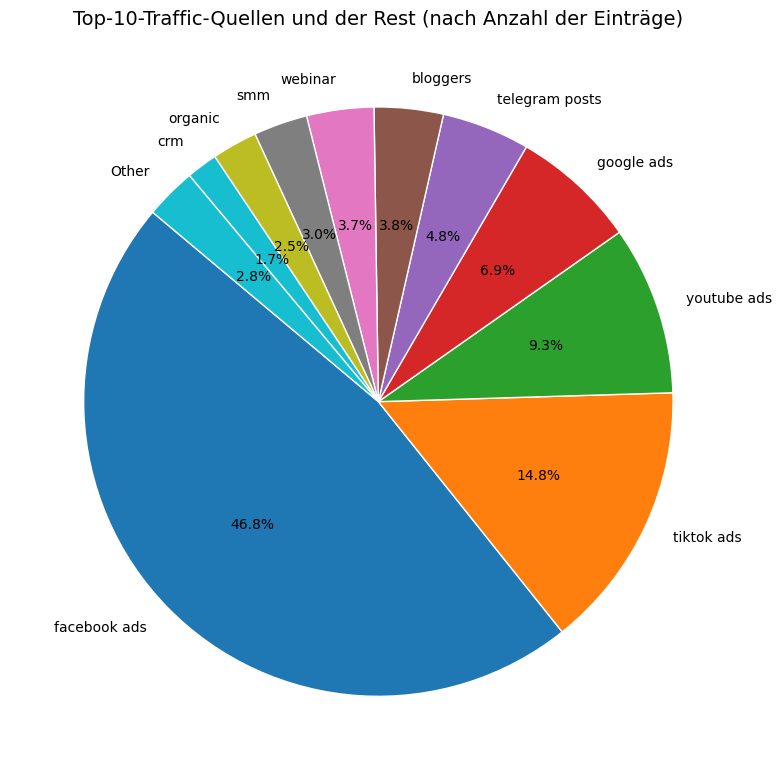

In [8]:
source_counts = spend['Source'].value_counts()

# 2. TOP 10 hervorheben und den Rest zusammenfassen
top_10 = source_counts.head(10)
others = pd.Series([source_counts.iloc[10:].sum()], index=['Other'])

# Zusammenführen in den finalen Datensatz für das Diagramm
plot_data = pd.concat([top_10, others])

# 3. Diagrammeinstellungen
plt.figure(figsize=(8, 8))

plot_data.plot(kind='pie', 
               autopct='%1.1f%%', 
               startangle=140, 
               cmap='tab10', # Satte, reine Farben
               wedgeprops={'edgecolor': 'white'}) # Weiße Ränder für mehr Klarheit hinzufügen


plt.title('Top-10-Traffic-Quellen und der Rest (nach Anzahl der Einträge)', fontsize=14)
plt.ylabel('')
plt.tight_layout() # Damit alle Beschriftungen hineinpassen

plt.show()

Das Diagramm verdeutlicht die Dominanz von Facebook und Google in der Traffic-Struktur. Die übrigen Quellen spielen eine untergeordnete Rolle, was auf eine starke Abhängigkeit der Marketingstrategie von den beiden größten Werbeplattformen hindeutet.

### DEALS

In [9]:
finance_metrics = ['Initial Amount Paid', 'Offer Total Amount', 'Successful Deal']

deals_stats = deals[finance_metrics].describe().loc[['mean', '50%', 'min', 'max']]
deals_stats.rename(index={'50%': 'median'}, inplace=True)


styled_deals = deals_stats.T.style.format('{:.2f}') \
    .background_gradient(cmap='Greens', subset=['mean', 'median'])

display(styled_deals)

,mean,median,min,max
Initial Amount Paid,919.96,1000.00,0.00,11000.00
Offer Total Amount,7169.25,11000.00,0.00,11500.00
Successful Deal,0.04,0.00,0.00,1.00


Niedrige Konversion: Nur 4 % (840) der Deals werden erfolgreich abgeschlossen. Dies deutet bei einer hohen Erreichbarkeitsquote (74 %) auf Probleme in der Verkaufsphase oder eine fehlende Übereinstimmung des Produkts mit den Erwartungen hin.

Preismodell: Die typischen Ausbildungskosten betragen 11.000, wobei die Standard-Erstabzahlung bei 1.000 liegt. Dies bestätigt die weite Verbreitung von Ratenzahlungssystemen zur Kundengewinnung.

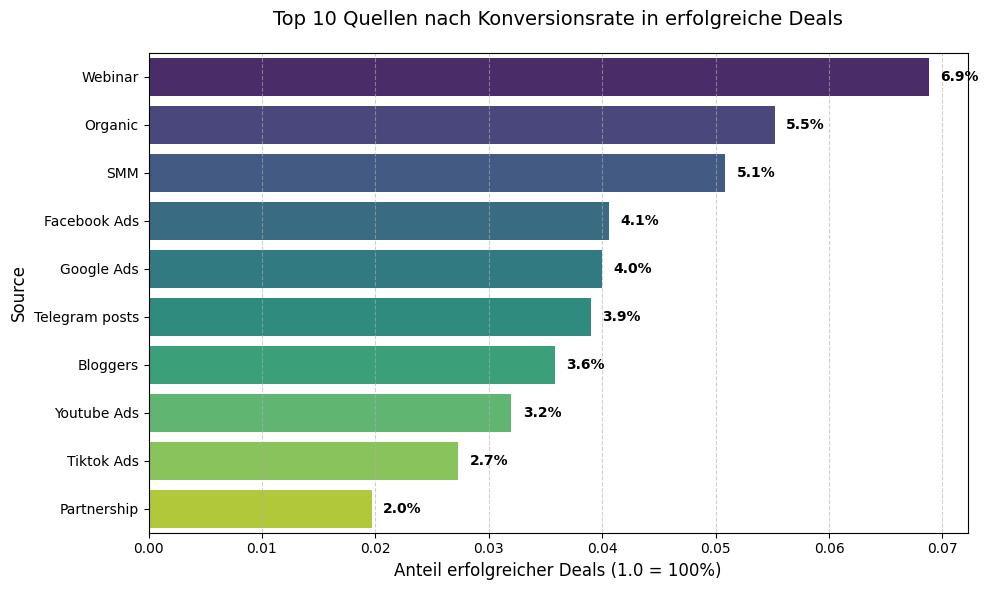

In [10]:
# 1. Konvertierung berechnen (Durchschnittswert von Successful Deal)
source_conversion = deals.groupby('Source')['Successful Deal'].mean().sort_values(ascending=False).head(10)


plt.figure(figsize=(10, 6))


ax = sns.barplot(
    x=source_conversion.values, 
    y=source_conversion.index, 
    hue=source_conversion.index, 
    palette='viridis', 
    legend=False
)


for i, v in enumerate(source_conversion.values):
    ax.text(v + 0.001, i, f'{v:.1%}', color='black', va='center', fontweight='bold')

# 5.Layout und Formatierung in russischer Sprache
plt.title('Top 10 Quellen nach Konversionsrate in erfolgreiche Deals', fontsize=14, pad=20)
plt.xlabel('Anteil erfolgreicher Deals (1.0 = 100%)', fontsize=12)
plt.ylabel('Source', fontsize=12)

# Raster zur besseren Lesbarkeit hinzufügen
plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Das Konvertierungsdiagramm verdeutlicht die Qualität der Zielgruppe: Webinare wandeln Zuschauer am effektivsten in Käufer um (6,9 %).

C:\Users\Kate Bruks\AppData\Local\Temp\ipykernel_16904\3860439625.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=source_money.values, y=source_money.index, palette='magma')


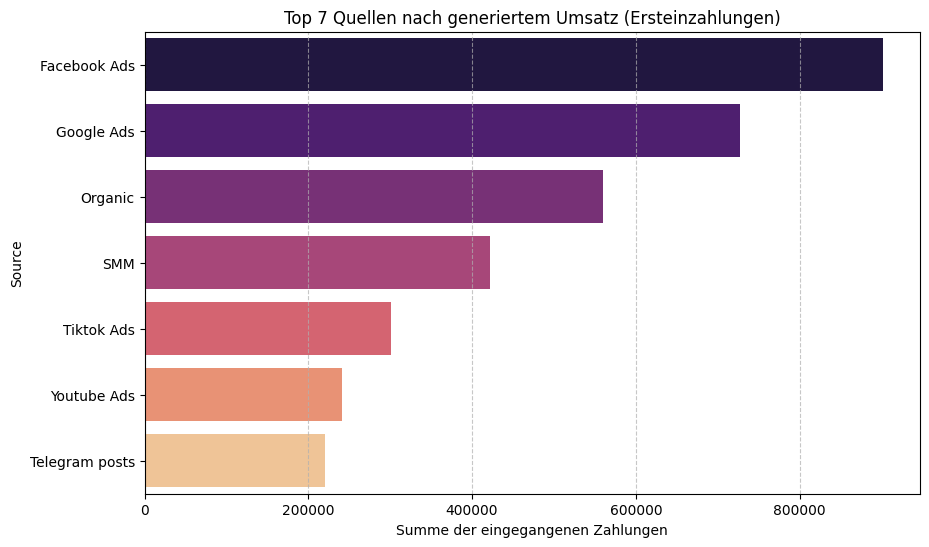

In [11]:
# Summe der tatsächlichen Zahlungen pro Quelle berechnen
source_money = deals.groupby('Source')['Initial Amount Paid'].sum().sort_values(ascending=False).head(7)


plt.figure(figsize=(10, 6))
sns.barplot(x=source_money.values, y=source_money.index, palette='magma')
plt.title('Top 7 Quellen nach generiertem Umsatz (Ersteinzahlungen)')
plt.xlabel('Summe der eingegangenen Zahlungen')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

Das Umsatzdiagramm verdeutlicht das Gesamtausmaß der Einnahmen: Facebook bringt das meiste Geld in die Kasse.

In [12]:
cols_to_analyze = ['Quality', 'Stage', 'Source', 'Product']

# 2. 2. describe() nur für diese aufrufen
#include='O' (der Buchstabe O) steht für "Object", also Textfelder

categorical_summary = deals[cols_to_analyze].describe(include='O')

display(categorical_summary.T)

,count,unique,top,freq
Quality,21590,7,E - Non Qualified,7632
Stage,21590,13,Lost,15741
Source,21590,13,Facebook Ads,4850
Product,13373,8,Digital Marketing,5718


In [13]:
final_product_stats = deals['Product'].value_counts()
final_product_percent = deals['Product'].value_counts(normalize=True) * 100

# In eine Tabelle zusammenführen
summary = pd.DataFrame({
    'Anzahl': final_product_stats,
    'Anteil (%)': final_product_percent
})

print("Aktualisierte Produktstatistik (nach Wiederherstellung):")
display(summary.head(10))

Aktualisierte Produktstatistik (nach Wiederherstellung):


,Anzahl,Anteil (%)
Product,,
Digital Marketing,5718,42.757796
Lead Magnet (Test),2282,17.064234
UX/UI Design,1779,13.302924
Web Developer,1346,10.065056
Lead Magnet (Workshop),1126,8.419951
Lead Magnet (Webinar),1117,8.352651
Find yourself in IT,4,0.029911
Data Analytics,1,0.007478


In [14]:
print(f"""
📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
🏆 **Absoluter Favorit: Digital Marketing.**
Der Haupttreiber für Nachfrage und Interesse in der Datenbank. Dieses Segment generiert den Großteil der Anfragen.

⚖️ **Solides Mittelfeld: UX/UI Design (13,3 %) und Web Developer (10 %).**
Für diese Kurse besteht eine stabile Nachfrage, jedoch hinken sie dem Spitzenreiter beim Lead-Volumen um das 3- bis 4-Fache hinterher.

⚠️ **Risikozone: Data Analytics und Find yourself in IT.**
Kritisch niedrige Zahlen (insgesamt nur 1 bzw. 4 Anfragen). Trotz der hohen Marktnachfrage nach Data Analytics kurbelt das interne 
Marketing derSchule dieses Segment überhaupt nicht an.

💡 **Empfehlung:**
Audit für den Analytics-Kurs durchführen. Wahrscheinlich sind Programm oder Preis gegenüber der Konkurrenz nicht wettbewerbsfähig,
oder es ist schlichtweg kein Werbetraffic auf dieses Segment ausgerichtet.
--------------------------------------------------------------------------------------------------
""")


📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
🏆 **Absoluter Favorit: Digital Marketing.**
Der Haupttreiber für Nachfrage und Interesse in der Datenbank. Dieses Segment generiert den Großteil der Anfragen.

⚖️ **Solides Mittelfeld: UX/UI Design (13,3 %) und Web Developer (10 %).**
Für diese Kurse besteht eine stabile Nachfrage, jedoch hinken sie dem Spitzenreiter beim Lead-Volumen um das 3- bis 4-Fache hinterher.

⚠️ **Risikozone: Data Analytics und Find yourself in IT.**
Kritisch niedrige Zahlen (insgesamt nur 1 bzw. 4 Anfragen). Trotz der hohen Marktnachfrage nach Data Analytics kurbelt das interne 
Marketing derSchule dieses Segment überhaupt nicht an.

💡 **Empfehlung:**
Audit für den Analytics-Kurs durchführen. Wahrscheinlich sind Programm oder Preis gegenüber der Konkurrenz nicht wettbewerbsfähig,
oder es ist schlichtweg kein Werbetraffic auf dieses Segment ausgerichtet.
------------------------------------

In [15]:
# Alle Ablehnungsgründe anzeigen
lost_analysis = deals[deals['Stage'] == 'Lost']['Lost Reason'].value_counts()
print("Hauptgründe für verlorene Deals:")
print(lost_analysis.head(10))


Hauptgründe für verlorene Deals:
Lost Reason
Doesn't Answer                 4073
Changed Decision               2122
Duplicate                      1745
Non target                     1736
Stopped Answering              1556
Invalid number                 1460
Expensive                       614
needs time to think             606
Conditions are not suitable     524
Inadequate                      174
Name: count, dtype: int64


In [16]:
print(f"""
📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
🕵️ **Gruppe „Karteileichen“: 7.089 Deals (~45 % aller Absagen).**
Hierzu zählen Nichterreichbarkeit, falsche Telefonnummern und Ignorieren. Es wird enorm viel Geld für Werbung ausgegeben, die „minderwertige“ Kontakte
generiert. Die Registrierungsformulare auf der Website müssen dringend überprüft werden.

🤔 **Gruppe „Meinung geändert“: ~3.800 Deals (Changed Decision + Non Target).**
Die Personen klicken entweder versehentlich auf den Button oder suchen nicht nach dem, was angeboten wird. Dies ist ein Signal dafür, dass die 
Werbemittel den Nutzer irreführen könnten.

💰 **Preis ist NICHT das Hauptproblem: Nur 614 Personen (< 4 % der Absagen) wählten „Expensive“.**
Ein Einwand hinsichtlich des Preises kommt 6-mal seltener vor als eine reine Nichterreichbarkeit.
💡 **Fazit-Strategie:**
Anstatt sich auf die Einwandbehandlung beim Preis zu konzentrieren, muss der Fokus darauf liegen, minderwertigen Traffic zu filtern und den Anrufprozess in den ersten Minuten nach der Anfrage zu optimieren.
--------------------------------------------------------------------------------------------------
""")


📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
🕵️ **Gruppe „Karteileichen“: 7.089 Deals (~45 % aller Absagen).**
Hierzu zählen Nichterreichbarkeit, falsche Telefonnummern und Ignorieren. Es wird enorm viel Geld für Werbung ausgegeben, die „minderwertige“ Kontakte
generiert. Die Registrierungsformulare auf der Website müssen dringend überprüft werden.

🤔 **Gruppe „Meinung geändert“: ~3.800 Deals (Changed Decision + Non Target).**
Die Personen klicken entweder versehentlich auf den Button oder suchen nicht nach dem, was angeboten wird. Dies ist ein Signal dafür, dass die 
Werbemittel den Nutzer irreführen könnten.

💰 **Preis ist NICHT das Hauptproblem: Nur 614 Personen (< 4 % der Absagen) wählten „Expensive“.**
Ein Einwand hinsichtlich des Preises kommt 6-mal seltener vor als eine reine Nichterreichbarkeit.
💡 **Fazit-Strategie:**
Anstatt sich auf die Einwandbehandlung beim Preis zu konzentrieren, muss der Fokus da

C:\Users\Kate Bruks\AppData\Local\Temp\ipykernel_16904\238377847.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=quality_pivot.index, y=quality_pivot.values, palette='Greens_r')


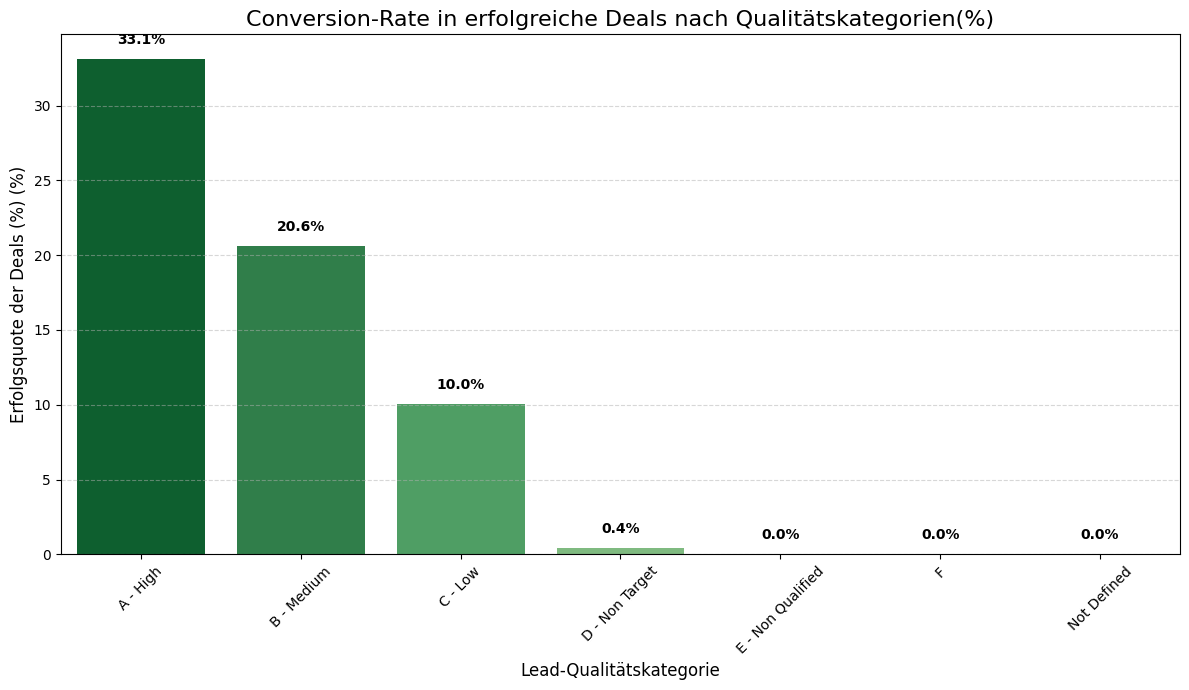

In [17]:
quality_pivot = deals.groupby('Quality')['Successful Deal'].mean().sort_values(ascending=False) * 100 

# Рисуем
plt.figure(figsize=(12, 7))
sns.barplot(x=quality_pivot.index, y=quality_pivot.values, palette='Greens_r') 


plt.title('Conversion-Rate in erfolgreiche Deals nach Qualitätskategorien(%)', fontsize=16)
plt.ylabel('Erfolgsquote der Deals (%) (%)', fontsize=12)
plt.xlabel('Lead-Qualitätskategorie', fontsize=12)
plt.xticks(rotation=45) 
plt.grid(axis='y', linestyle='--', alpha=0.5)

for i, v in enumerate(quality_pivot.values):
    plt.text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [18]:
print(f"""
📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
🎯 **Effizienz des Scorings: Kategorie A (High) kauft in 33 % der Fälle.**
Das ist 8-mal häufiger als der durchschnittliche Kunde in der Datenbank! Das Lead-Bewertungssystem funktioniert und identifiziert das „Gold“ präzise.

💸 **Unnötige Kosten: Kategorien D, E und F weisen eine Conversion-Rate von nahezu Null auf.**
Ein riesiger Teil des Werbebudgets fließt in die Gewinnung „wertloser“ Anfragen, die keine Einnahmen bringen.

🚀 **Wachstumsbereich: Qualität schlägt Quantität.**
Um das Geschäft zu skalieren, darf nicht der allgemeine Lead-Fluss erhöht werden; stattdessen müssen Wege gefunden werden, gezielt Zielgruppen der
Stufen A und B anzusprechen.

💡 **Fazit-Strategie:**
Umschichtung des Werbebudgets von Kampagnen mit hoher Reichweite auf zielgerichtetes Targeting – mit klarem Fokus auf das Profil des idealen Kunden 
aus Kategorie A.
--------------------------------------------------------------------------------------------------
""")


📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
🎯 **Effizienz des Scorings: Kategorie A (High) kauft in 33 % der Fälle.**
Das ist 8-mal häufiger als der durchschnittliche Kunde in der Datenbank! Das Lead-Bewertungssystem funktioniert und identifiziert das „Gold“ präzise.

💸 **Unnötige Kosten: Kategorien D, E und F weisen eine Conversion-Rate von nahezu Null auf.**
Ein riesiger Teil des Werbebudgets fließt in die Gewinnung „wertloser“ Anfragen, die keine Einnahmen bringen.

🚀 **Wachstumsbereich: Qualität schlägt Quantität.**
Um das Geschäft zu skalieren, darf nicht der allgemeine Lead-Fluss erhöht werden; stattdessen müssen Wege gefunden werden, gezielt Zielgruppen der
Stufen A und B anzusprechen.

💡 **Fazit-Strategie:**
Umschichtung des Werbebudgets von Kampagnen mit hoher Reichweite auf zielgerichtetes Targeting – mit klarem Fokus auf das Profil des idealen Kunden 
aus Kategorie A.
------------------------------

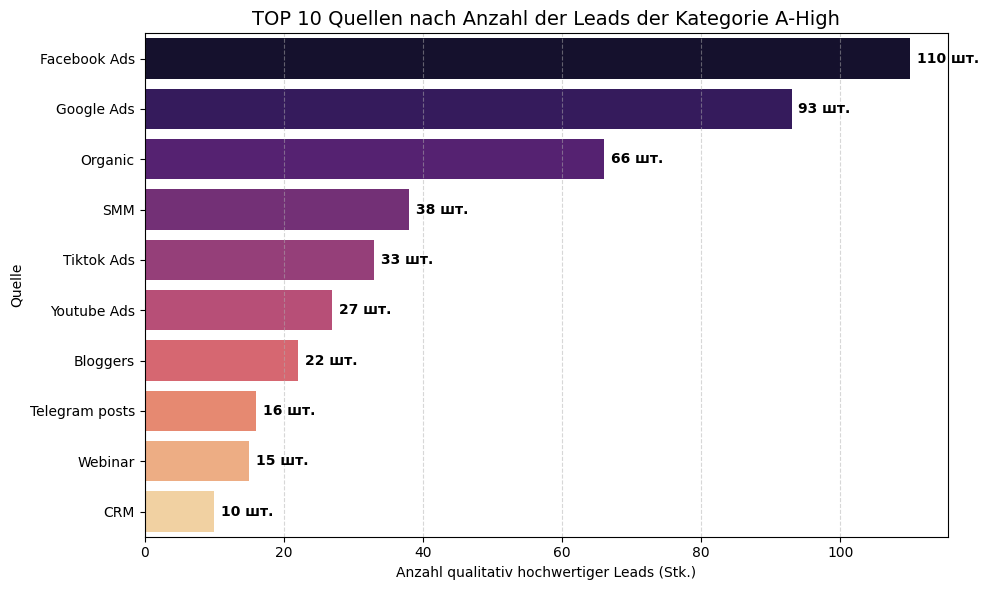

In [19]:
# 1. Anzahl der Leads der Kategorie 'A - High' pro Quelle berechnen
high_quality_leads = deals[deals['Quality'] == 'A - High'].groupby('Source').size().sort_values(ascending=False).head(10)


plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x=high_quality_leads.values, 
    y=high_quality_leads.index, 
    hue=high_quality_leads.index, 
    palette='magma', 
    legend=False
)


for i, v in enumerate(high_quality_leads.values):
    ax.text(v + 1, i, f'{int(v)} шт.', va='center', fontweight='bold')

plt.title('TOP 10 Quellen nach Anzahl der Leads der Kategorie A-High', fontsize=14)
plt.xlabel('Anzahl qualitativ hochwertiger Leads (Stk.)')
plt.ylabel('Quelle')
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [20]:
print(f"""
📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
🚀 **Spitzenreiter auf allen Fronten: Facebook und Google Ads.**
Sorgen für den massivsten Lead-Fluss und bringen die meisten „Gold“-Anfragen (Kategorie A-High).

💎 **Qualität vs. Volumen: Webinar und Organic.**
Webinare weisen eine Rekord-Conversion-Rate von 7,58 % auf, während organischer Traffic die beste Balance zwischen hoher Lead-Anzahl und 
hervorragender Qualität bietet (66 Leads der Kategorie A).

⚠️ **Bereich geringer Effizienz: CRM und TikTok Ads.**
CRM verzeichnet die niedrigste Conversion-Rate (1,75 %) und die wenigsten qualifizierten Anfragen. TikTok bringt zwar viel Traffic, hinkt
jedoch bei Qualität und Conversion-Rate (3,4 %) deutlich hinter der Konkurrenz hinterher.

💡 **Fazit-Strategie:**
Facebook/Google zur Volumensteigerung skalieren und zeitgleich Organic/Webinare ausbauen, um das hohe Qualitätsniveau nachhaltig zu sichern.
--------------------------------------------------------------------------------------------------
""")


📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
🚀 **Spitzenreiter auf allen Fronten: Facebook und Google Ads.**
Sorgen für den massivsten Lead-Fluss und bringen die meisten „Gold“-Anfragen (Kategorie A-High).

💎 **Qualität vs. Volumen: Webinar und Organic.**
Webinare weisen eine Rekord-Conversion-Rate von 7,58 % auf, während organischer Traffic die beste Balance zwischen hoher Lead-Anzahl und 
hervorragender Qualität bietet (66 Leads der Kategorie A).

⚠️ **Bereich geringer Effizienz: CRM und TikTok Ads.**
CRM verzeichnet die niedrigste Conversion-Rate (1,75 %) und die wenigsten qualifizierten Anfragen. TikTok bringt zwar viel Traffic, hinkt
jedoch bei Qualität und Conversion-Rate (3,4 %) deutlich hinter der Konkurrenz hinterher.

💡 **Fazit-Strategie:**
Facebook/Google zur Volumensteigerung skalieren und zeitgleich Organic/Webinare ausbauen, um das hohe Qualitätsniveau nachhaltig zu sichern.
---------------------

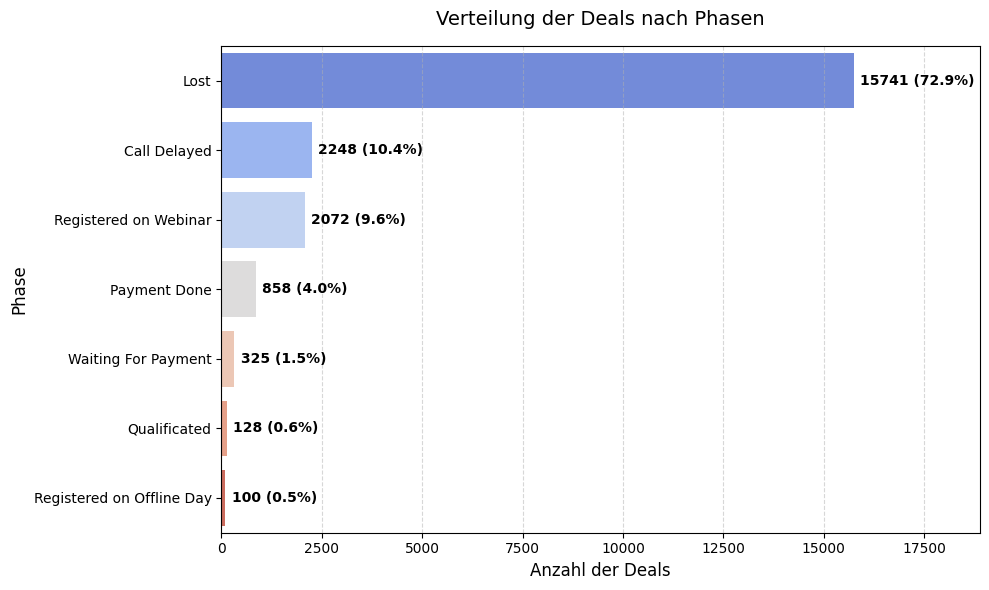

In [21]:
stage_counts = deals['Stage'].value_counts().head(7)
total_deals = len(deals)


plt.figure(figsize=(10, 6)) 

ax = sns.barplot(
    x=stage_counts.values, 
    y=stage_counts.index, 
    hue=stage_counts.index, 
    palette='coolwarm', 
    legend=False
)

max_val = stage_counts.values.max()
plt.xlim(0, max_val * 1.2) 

for i, v in enumerate(stage_counts.values):
    percentage = (v / total_deals) * 100
    ax.text(v + (max_val * 0.01), i, f"{v} ({percentage:.1f}%)", 
            va='center', fontweight='bold', color='black')

plt.title('Verteilung der Deals nach Phasen', fontsize=14, pad=15)
plt.xlabel('Anzahl der Deals', fontsize=12)
plt.ylabel('Phase', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [22]:
print(f"""
📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
📉 **Kritischer Verlust: 73 % der Deals (15.741 Stk.) befinden sich im Status „Lost“.**
Ein enormer Verlust potenzieller Kunden findet bereits in den frühesten Phasen des Funnels statt.

⏳ **Stau im System: 10 % der Deals stecken in „Call Delayed“ fest.**
Dies deutet auf eine verdeckte Absage oder Versäumnisse der Vertriebsmitarbeiter hin. Leads „verfallen“, wenn sie nicht rechtzeitig kontaktiert werden.

💰 **Echte Effizienz: Der Status „Payment Done“ liegt bei lediglich 4 %.**
Der Funnel arbeitet extrem uneffizient und wandelt nur einen winzigen Teil des eingehenden Traffics in tatsächlichen Umsatz um.

💡 **Fazit-Strategie:**
Statt das Werbebudget zu erhöhen, müssen strikte Anruf-Prozesse und eine automatische Phasen-Kontrolle eingeführt werden, um die Verluste in den ersten 24 Stunden
nach der Anfrage drastisch zu reduzieren.
--------------------------------------------------------------------------------------------------
""")


📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
📉 **Kritischer Verlust: 73 % der Deals (15.741 Stk.) befinden sich im Status „Lost“.**
Ein enormer Verlust potenzieller Kunden findet bereits in den frühesten Phasen des Funnels statt.

⏳ **Stau im System: 10 % der Deals stecken in „Call Delayed“ fest.**
Dies deutet auf eine verdeckte Absage oder Versäumnisse der Vertriebsmitarbeiter hin. Leads „verfallen“, wenn sie nicht rechtzeitig kontaktiert werden.

💰 **Echte Effizienz: Der Status „Payment Done“ liegt bei lediglich 4 %.**
Der Funnel arbeitet extrem uneffizient und wandelt nur einen winzigen Teil des eingehenden Traffics in tatsächlichen Umsatz um.

💡 **Fazit-Strategie:**
Statt das Werbebudget zu erhöhen, müssen strikte Anruf-Prozesse und eine automatische Phasen-Kontrolle eingeführt werden, um die Verluste in den ersten 24 Stunden
nach der Anfrage drastisch zu reduzieren.
---------------------------------------